installing from requirements yield and error just like in the other 2 tasks so i'm forced to install the latest versions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 2666
np.random.seed(SEED)

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (32940, 22)
Test shape: (8236, 20)


In [2]:
# Compare columns between train and test
train_cols = set(train_df.columns)
test_cols = set(test_df.columns)

missing_in_test = train_cols - test_cols
extra_in_test = test_cols - train_cols

print("Columns in train but missing in test:", missing_in_test)
print("Columns in test but missing in train:", extra_in_test)

Columns in train but missing in test: {'duration', 'y'}
Columns in test but missing in train: set()


In [3]:
target_counts = train_df['y'].value_counts()
target_proportions = train_df['y'].value_counts(normalize=True) * 100

print("Target Counts:")
print(target_counts)
print("\nTarget Proportions (%):")
print(target_proportions)

majority_acc = target_proportions.max()
print(f"\nMajority-class accuracy (always predicting 'no'): {majority_acc:.2f}%")

Target Counts:
y
no     29229
yes     3711
Name: count, dtype: int64

Target Proportions (%):
y
no     88.734062
yes    11.265938
Name: proportion, dtype: float64

Majority-class accuracy (always predicting 'no'): 88.73%


# Stage 2

In [4]:
print("--- Data Info ---")
train_df.info()

print("\n--- 'unknown' counts in categorical columns ---")
cat_cols = train_df.select_dtypes(include=['object']).columns
for col in cat_cols:
    unknown_count = (train_df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"{col}: {unknown_count} unknowns ({unknown_count/len(train_df)*100:.2f}%)")

print("\n--- Numerical Summary ---")
print(train_df[['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'euribor3m']].describe())

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 32940 entries, 0 to 32939
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              32940 non-null  int64  
 1   age             32940 non-null  int64  
 2   job             32940 non-null  str    
 3   marital         32940 non-null  str    
 4   education       32940 non-null  str    
 5   default         32940 non-null  str    
 6   housing         32940 non-null  str    
 7   loan            32940 non-null  str    
 8   contact         32940 non-null  str    
 9   month           32940 non-null  str    
 10  day_of_week     32940 non-null  str    
 11  duration        32940 non-null  int64  
 12  campaign        32940 non-null  int64  
 13  pdays           32940 non-null  int64  
 14  previous        32940 non-null  int64  
 15  poutcome        32940 non-null  str    
 16  emp.var.rate    32940 non-null  float64
 17  cons.price.idx  32940 no

C:\Users\aibek\AppData\Local\Temp\ipykernel_32032\4221388039.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train_df.select_dtypes(include=['object']).columns


C:\Users\aibek\AppData\Local\Temp\ipykernel_32032\4290723680.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='y', y='euribor3m', ax=axes[1], palette='Pastel1')


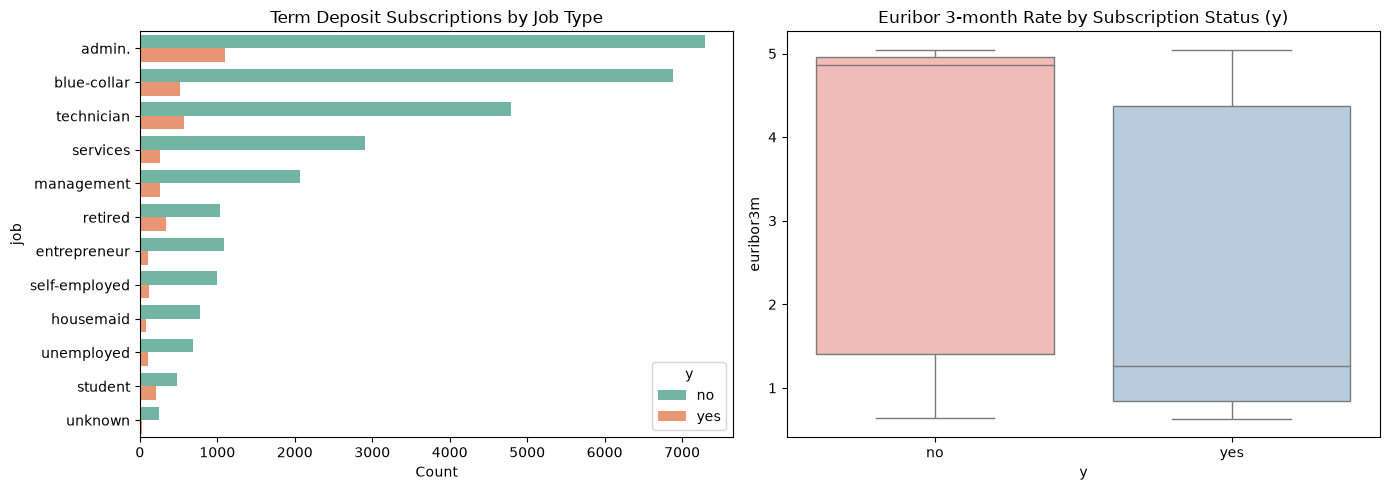

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train_df, y='job', hue='y', order=train_df['job'].value_counts().index, ax=axes[0], palette='Set2')
axes[0].set_title('Term Deposit Subscriptions by Job Type')
axes[0].set_xlabel('Count')

sns.boxplot(data=train_df, x='y', y='euribor3m', ax=axes[1], palette='Pastel1')
axes[1].set_title('Euribor 3-month Rate by Subscription Status (y)')

plt.tight_layout()
plt.show()

# Stage 3

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Drop 'duration' and 'id' from features (and separate target 'y')
X = train_df.drop(columns=['id', 'y', 'duration'], errors='ignore')
y = train_df['y'].map({'yes': 1, 'no': 0}) # Map target to binary

# 2. Set aside your own hold-out set (e.g., 20%) for final evaluation in Stage 7
# Remember to use your student ID seed (replace 1234 with your last 4 digits)
SEED = 1234
X_train_cv, X_holdout, y_train_cv, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"CV Training set shape: {X_train_cv.shape}")
print(f"Hold-out set shape: {X_holdout.shape}")

# 3. Define Stratified K-Fold for cross-validation on the training part
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Cross-validation splitter ready with {cv.n_splits} folds.")

CV Training set shape: (26352, 19)
Hold-out set shape: (6588, 19)
Cross-validation splitter ready with 5 folds.


# Stage 4